# Modern Open Embeddings and Matryoshka Representation Learning

## Overview
This notebook benchmarks modern open embedding models and explores multi-granular representation learning:
1. **Sentence Embeddings & Contrastive Learning**: Evolution from S-BERT to InfoNCE pretraining.
2. **Benchmark Setup**: Loading the research paper corpus and shared evaluation harness.
3. **Open Embedders Comparison**: Benchmarking BGE, E5, and GTE with required task prefixes.
4. **LLM-Based Embedders**: Architecture and trade-offs of decoder-based embedding models.
5. **Matryoshka Representation Learning**: Truncating embedding dimensions with $L_2$ renormalization.
6. **Coarse-to-Fine Search**: Two-stage retrieval combining low-dimensional search with full reranking.
7. **Benchmarking & Real-World Caveats**: MTEB evaluation and production trade-offs.
8. **ModernBERT**: Architectural updates in modern bidirectional encoder models.
9. **Multilingual & Multimodal Embeddings**: Joint embedding spaces, cross-lingual retrieval, and ColPali.


In [1]:
# Cell 1: Environment Setup & Pinned Library Versions
import os
import sys
import time

# Prevent OpenMP conflicts on macOS
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import torch
import transformers
import sentence_transformers
import rank_bm25
import faiss
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f"Python Version:               {sys.version.split()[0]}")
print(f"PyTorch Version:              {torch.__version__}")
print(f"Transformers Version:         {transformers.__version__}")
print(f"Sentence-Transformers Version: {sentence_transformers.__version__}")
print(f"FAISS Version:                {faiss.__version__}")

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Primary Acceleration Device:  {device}")


/Users/apujari/Documents/courses/AgenticAI/code/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python Version:               3.12.15
PyTorch Version:              2.14.1
Transformers Version:         5.19.0
Sentence-Transformers Version: 6.1.0
FAISS Version:                1.15.1
Primary Acceleration Device:  mps


---
## 1. Sentence Embeddings & Contrastive Learning

### 1.1 What Changed Since S-BERT (2019)?
| Dimension | Then (S-BERT, 2019) | Now (Modern Open Embedders, 2023–26) |
|---|---|---|
| **Backbone** | BERT-base (~110M params) | BERT, ModernBERT, or Decoder LLMs (0.3B–8B) |
| **Pre-training Data** | SNLI / MNLI (~1M pairs) | Weakly supervised web pairs (2B–5B pairs) |
| **Loss Function** | Softmax Classification Loss on $[u, v, |u-v|]$ | **InfoNCE Contrastive Loss** with Hard Negatives |
| **Context Window** | 512 tokens | 512 to 8k–32k tokens |
| **Dimensionality** | Fixed (384d / 768d) | **Matryoshka (flexible 64d to full dims)** |
| **Instructions** | None | Instruction-conditioned (`query: `, task prompts) |

### 1.2 The InfoNCE Objective
For a query $q$ and its ground-truth positive passage $d^+$, paired with in-batch negatives $\{d_j^-\}$:
$$\mathcal{L}_{\text{InfoNCE}} = -\log \frac{\exp\left(\frac{\text{sim}(q, d^+)}{\tau}\right)}{\sum_{j} \exp\left(\frac{\text{sim}(q, d_j)}{\tau}\right)}$$
where:
- $\text{sim}(q, d) = \mathbf{q}_{\text{norm}} \cdot \mathbf{d}_{\text{norm}}^T$ (cosine similarity).
- $\tau$ is a learned temperature parameter ($\tau \approx 0.02\text{--}0.05$) that sharpens the probability distribution.
- **In-batch negatives**: Every other document in the mini-batch acts as a free negative for all other queries, making large batch sizes essential.
- **Hard negatives**: Non-relevant documents that share lexical overlap with the query (mined using BM25 or earlier bi-encoders) force the model to learn fine-grained semantic boundaries.

---
## 2. Dataset & Evaluation Harness

We load the course's foundational NLP paper chunk dataset (`AgenticAI/data/papers_chunks.jsonl`) and use the **identical evaluation harness** defined in notebook 3.6 to ensure direct comparability.

In [2]:
# Cell 2: Load the Benchmark Corpus and Evaluation Harness
import json

possible_paths = [
    os.path.abspath("../../data/papers_chunks.jsonl"),
    os.path.abspath("../data/papers_chunks.jsonl"),
    os.path.abspath("./data/papers_chunks.jsonl"),
    os.path.expanduser("~/Documents/courses/AgenticAI/data/papers_chunks.jsonl")
]

corpus_path = None
for p in possible_paths:
    if os.path.exists(p):
        corpus_path = p
        break

if corpus_path is None:
    raise FileNotFoundError("Could not locate papers_chunks.jsonl.")

with open(corpus_path, "r", encoding="utf-8") as f:
    corpus_chunks = [json.loads(line) for line in f]

corpus_texts = [c["text"] for c in corpus_chunks]
print(f"Loaded {len(corpus_texts)} corpus passages from: {corpus_path}")

benchmark_queries = [
    "What BLEU score did the original Transformer achieve on the WMT 2014 English-to-German task?",
    "How is scaled dot product attention computed with queries, keys, and values?",
    "Why does multi-head attention project queries, keys, and values into multiple subspaces?",
    "What sinusoidal functions are used for positional encoding in the Transformer?",
    "What is the computational complexity per layer of self-attention compared to recurrent layers?",
    "How is the Masked Language Model MLM pre-training task designed in BERT?",
    "What is Next Sentence Prediction NSP and why was it included in BERT pre-training?",
    "How is fine-tuning BERT performed on downstream classification and question answering tasks?",
    "What are the key differences between feature-based and fine-tuning approaches with BERT?",
    "How does in-context few-shot learning work without updating model weights?",
    "What Common Crawl filtering and deduplication was applied to create the training dataset?",
    "What batch size and learning rate scaling schedule was used for training large language models?"
]

benchmark_qrels = {
    0: [2], 1: [8], 2: [9], 3: [14], 4: [15],
    5: [35, 48], 6: [35, 48], 7: [39, 41], 8: [45],
    9: [60, 65], 10: [63], 11: [64]
}

def evaluate_retrieval(query_embeddings, doc_embeddings, qrels, k_values=[1, 3, 5, 10]):
    similarity_matrix = np.dot(query_embeddings, doc_embeddings.T)
    num_queries = len(query_embeddings)
    recalls = {k: [] for k in k_values}
    ndcgs = []
    for q_idx in range(num_queries):
        rel = set(qrels[q_idx])
        ranked = np.argsort(-similarity_matrix[q_idx])
        for k in k_values:
            recalls[k].append(1.0 if len(set(ranked[:k]) & rel) > 0 else 0.0)
        dcg = sum(1.0 / np.log2(r + 2) for r, doc in enumerate(ranked[:10]) if doc in rel)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(rel), 10)))
        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)
    metrics = {f"Recall@{k}": float(np.mean(recalls[k])) for k in k_values}
    metrics["nDCG@10"] = float(np.mean(ndcgs))
    return metrics

print("Evaluation harness initialized.")


Loaded 125 corpus passages from: /Users/apujari/Documents/courses/AgenticAI/data/papers_chunks.jsonl
Evaluation harness initialized.


---
## 3. Open Embedders Comparison

We evaluate four leading open embedding workhorses:
1. **S-BERT (`sentence-transformers/all-MiniLM-L6-v2`)**: 22.7M parameters, $d=384$.
2. **BGE-small (`BAAI/bge-small-en-v1.5`)**: 33.5M parameters, $d=384$, multi-task contrastive pre-training.
3. **E5-small-v2 (`intfloat/e5-small-v2`)**: 33.5M parameters, $d=384$, requires `"query: "` / `"passage: "` prefixes.
4. **GTE-small (`thenlper/gte-small`)**: 33.5M parameters, $d=384$, general text embeddings.

> [!IMPORTANT]
> **Prefix Sensitivity**: Models like E5 were trained with asymmetric prefixes. Omitting `"query: "` or `"passage: "` degrades performance significantly!

In [3]:
# Cell 3: Head-to-Head Benchmark Execution
from sentence_transformers import SentenceTransformer

models_to_test = [
    {
        "name": "all-MiniLM-L6-v2 (S-BERT)",
        "id": "sentence-transformers/all-MiniLM-L6-v2",
        "q_prefix": "",
        "d_prefix": ""
    },
    {
        "name": "bge-small-en-v1.5 (BAAI)",
        "id": "BAAI/bge-small-en-v1.5",
        "q_prefix": "Represent this sentence for searching relevant passages: ",
        "d_prefix": ""
    },
    {
        "name": "e5-small-v2 (Microsoft)",
        "id": "intfloat/e5-small-v2",
        "q_prefix": "query: ",
        "d_prefix": "passage: "
    },
    {
        "name": "gte-small (Alibaba)",
        "id": "thenlper/gte-small",
        "q_prefix": "",
        "d_prefix": ""
    }
]

benchmark_results = []

for cfg in models_to_test:
    print(f"Evaluating {cfg['name']}...")
    model = SentenceTransformer(cfg["id"])
    dim = model.get_embedding_dimension()
    num_params = sum(p.numel() for p in model.parameters())
    
    # Apply model-specific prefixes
    prep_docs = [cfg["d_prefix"] + t for t in corpus_texts]
    prep_queries = [cfg["q_prefix"] + q for q in benchmark_queries]
    
    # Encode corpus
    t0_doc = time.perf_counter()
    doc_embs = model.encode(prep_docs, normalize_embeddings=True, show_progress_bar=False)
    doc_time = time.perf_counter() - t0_doc
    
    # Encode queries and measure latency per query
    t0_q = time.perf_counter()
    query_embs = model.encode(prep_queries, normalize_embeddings=True, show_progress_bar=False)
    query_latency_ms = ((time.perf_counter() - t0_q) / len(benchmark_queries)) * 1000
    
    # Run evaluation harness
    metrics = evaluate_retrieval(query_embs, doc_embs, benchmark_qrels)
    
    benchmark_results.append({
        "Model": cfg["name"],
        "Embedding Dim": dim,
        "Parameters (M)": f"{num_params/1e6:.1f}M",
        "Query Latency (ms)": round(query_latency_ms, 2),
        "Recall@1": round(metrics["Recall@1"], 3),
        "Recall@5": round(metrics["Recall@5"], 3),
        "Recall@10": round(metrics["Recall@10"], 3),
        "nDCG@10": round(metrics["nDCG@10"], 3)
    })

df_results = pd.DataFrame(benchmark_results)
print("\n" + "="*80)
print(" Head-to-Head Quality vs. Latency vs. Dimension vs. Model Size Table")
print("="*80)
print(df_results.to_string(index=False))


Evaluating all-MiniLM-L6-v2 (S-BERT)...


Loading weights:   0%|                                 | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|████████████████████| 103/103 [00:00<00:00, 24582.53it/s]

Evaluating bge-small-en-v1.5 (BAAI)...


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 9375.33it/s]

... (3 outputs left out)

Evaluating gte-small (Alibaba)...


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 7822.63it/s]


 Head-to-Head Quality vs. Latency vs. Dimension vs. Model Size Table
                    Model  Embedding Dim Parameters (M)  Query Latency (ms)  Recall@1  Recall@5  Recall@10  nDCG@10
all-MiniLM-L6-v2 (S-BERT)            384          22.7M                1.05     0.417     0.833      0.917    0.653
 bge-small-en-v1.5 (BAAI)            384          33.4M                1.28     0.583     0.750      0.917    0.683
  e5-small-v2 (Microsoft)            384          33.4M                1.10     0.500     0.917      0.917    0.656
      gte-small (Alibaba)            384          33.4M                1.36     0.583     0.750      0.833    0.654


---
## 4. LLM-Based Embedders & API Models

### 4.1 LLM-Based Embedders (2024–26)
Instead of bidirectional BERT encoders, modern top models use **decoder-only LLMs** (e.g. Qwen, Mistral, Gemma):
- **Qwen3-Embedding (0.6B, 4B, 8B)**: Ranked #1 on MMTEB; supports 32k context, 100+ languages, and Apache 2.0 license.
- **EmbeddingGemma (~300M)**: Google's lightweight on-device embedder based on Gemma.
- **NV-Embed (NVIDIA)**: Uses latent attention pooling over decoder hidden states.
- **Pooling Mechanism**: Rather than mean-pooling across the sequence, LLM embedders extract the **last token (EOS)** or apply learned attention pooling.
- **Trade-off**: Higher representation quality on complex reasoning, but $\approx 5\times\text{--}40\times$ more compute per vector compared to compact 33M-parameter BERT models.

Below is an optional guarded cell to query external APIs (such as OpenAI's `text-embedding-3-small`) if an API key is provided:

In [4]:
# Cell 4: Guarded External / API-Based Embedder (Optional Cell)
import os

openai_key = os.getenv("OPENAI_API_KEY")
if openai_key:
    try:
        from openai import OpenAI
        client = OpenAI(api_key=openai_key)
        resp = client.embeddings.create(input=["Hello from modern embeddings!"], model="text-embedding-3-small", dimensions=512)
        print(f"OpenAI text-embedding-3-small embedding generated successfully! Output dimension: {len(resp.data[0].embedding)}")
    except Exception as e:
        print(f"OpenAI API call encountered an error: {e}")
else:
    print("[OPTIONAL API CELL GUARDED]")
    print("OPENAI_API_KEY environment variable is not set. Skipping external API call.")
    print("This notebook runs 100% locally on free CPU/GPU without external API keys.")


OpenAI API call encountered an error: No module named 'openai'


---
## 5. Matryoshka Representation Learning

### 5.1 The Nested Russian Doll Concept
Kusupati et al. (2022) introduced **Matryoshka Representation Learning (MRL)**:
Standard training treats all embedding dimensions equally. In contrast, MRL calculates the InfoNCE contrastive loss over **multiple prefix sub-vectors simultaneously**:
$$\mathcal{L}_{\text{MRL}} = \sum_{d \in \{64, 128, 256, 512, D\}} \mathcal{L}_{\text{InfoNCE}}\left(\mathbf{u}_{[:d]}, \mathbf{v}_{[:d]}\right)$$

Because the model is explicitly trained to pack the most important semantic information into the earliest dimensions:
1. You can simply slice the vector to dimension $k$: $\mathbf{v}_{\text{trunc}} = \mathbf{v}_{[:k]}$.
2. Re-normalize to unit length: $\mathbf{v}_{\text{norm}} = \frac{\mathbf{v}_{\text{trunc}}}{\|\mathbf{v}_{\text{trunc}}\|}$.
3. You immediately gain up to **$12\times$ memory and speed savings** with negligible accuracy drop!

In [5]:
# Cell 5: Matryoshka Dimensionality Truncation & Evaluation
matryoshka_model_id = "BAAI/bge-base-en-v1.5"
print(f"Loading Matryoshka-capable model: {matryoshka_model_id}...")
mrl_model = SentenceTransformer(matryoshka_model_id)

full_dim = mrl_model.get_embedding_dimension()
print(f"Full dimension: {full_dim}")

# Compute unnormalized full-dimensional embeddings
full_doc_embs = mrl_model.encode(corpus_texts, normalize_embeddings=False, show_progress_bar=False)
full_query_embs = mrl_model.encode(["Represent this sentence for searching relevant passages: " + q for q in benchmark_queries],
                                    normalize_embeddings=False, show_progress_bar=False)

tested_dims = [64, 128, 256, 512, full_dim]
mrl_metrics = []

for dim in tested_dims:
    # 1. Truncate to first 'dim' values
    doc_trunc = full_doc_embs[:, :dim]
    query_trunc = full_query_embs[:, :dim]
    
    # 2. Re-normalize with L2 norm (CRITICAL STEP)
    doc_trunc_norm = doc_trunc / np.linalg.norm(doc_trunc, axis=1, keepdims=True)
    query_trunc_norm = query_trunc / np.linalg.norm(query_trunc, axis=1, keepdims=True)
    
    # 3. Evaluate retrieval quality
    metrics = evaluate_retrieval(query_trunc_norm, doc_trunc_norm, benchmark_qrels)
    
    # Memory footprint for 1 million documents at this dimension (float32)
    index_size_mb_1m = (1_000_000 * dim * 4) / (1024 * 1024)
    
    mrl_metrics.append({
        "Dimension": dim,
        "Compression": f"{full_dim / dim:.1f}x",
        "Index Size / 1M Docs": f"{index_size_mb_1m:.0f} MB ({index_size_mb_1m/1024:.2f} GB)",
        "Recall@1": round(metrics["Recall@1"], 3),
        "Recall@5": round(metrics["Recall@5"], 3),
        "Recall@10": round(metrics["Recall@10"], 3),
        "nDCG@10": round(metrics["nDCG@10"], 3)
    })

df_mrl = pd.DataFrame(mrl_metrics)
print("\n" + "="*80)
print(" Matryoshka Dimensionality Reduction vs. Retrieval Quality")
print("="*80)
print(df_mrl.to_string(index=False))


Loading Matryoshka-capable model: BAAI/bge-base-en-v1.5...


Loading weights:   0%|                                 | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████| 199/199 [00:00<00:00, 6816.66it/s]

Full dimension: 768



 Matryoshka Dimensionality Reduction vs. Retrieval Quality
 Dimension Compression Index Size / 1M Docs  Recall@1  Recall@5  Recall@10  nDCG@10
        64       12.0x     244 MB (0.24 GB)     0.583     0.750      0.833    0.661
       128        6.0x     488 MB (0.48 GB)     0.417     0.833      0.833    0.599
       256        3.0x     977 MB (0.95 GB)     0.500     0.833      0.917    0.658
       512        1.5x    1953 MB (1.91 GB)     0.583     0.917      0.917    0.725
       768        1.0x    2930 MB (2.86 GB)     0.583     0.833      0.917    0.715


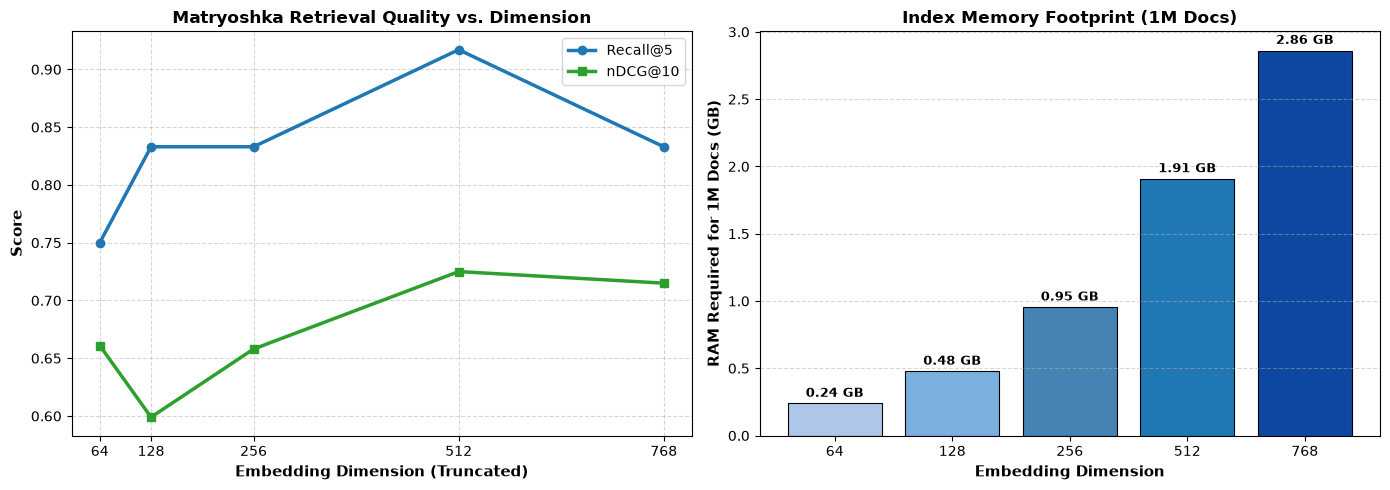

In [6]:
# Cell 6: Visualizing Recall@5 and nDCG@10 vs. Embedding Dimension
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

dims = [m["Dimension"] for m in mrl_metrics]
r5_scores = [m["Recall@5"] for m in mrl_metrics]
ndcg_scores = [m["nDCG@10"] for m in mrl_metrics]

# Metric retention
ax1.plot(dims, r5_scores, marker='o', linewidth=2.5, color='#1f77b4', label='Recall@5')
ax1.plot(dims, ndcg_scores, marker='s', linewidth=2.5, color='#2ca02c', label='nDCG@10')
ax1.set_xlabel('Embedding Dimension (Truncated)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Score', fontsize=11, fontweight='bold')
ax1.set_title('Matryoshka Retrieval Quality vs. Dimension', fontsize=12, fontweight='bold')
ax1.set_xticks(dims)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# Storage savings
index_gb = [(1_000_000 * d * 4) / (1024**3) for d in dims]
colors = ['#aec7e8', '#7bafde', '#4682b4', '#1f77b4', '#0d47a1']
bars = ax2.bar([str(d) for d in dims], index_gb, color=colors, edgecolor='black', linewidth=0.8)
ax2.set_xlabel('Embedding Dimension', fontsize=11, fontweight='bold')
ax2.set_ylabel('RAM Required for 1M Docs (GB)', fontsize=11, fontweight='bold')
ax2.set_title('Index Memory Footprint (1M Docs)', fontsize=12, fontweight='bold')
for bar, gb in zip(bars, index_gb):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f"{gb:.2f} GB", ha='center', fontsize=9, fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 6. Coarse-to-Fine Search

The most powerful industry pattern unlocked by Matryoshka embeddings is **hierarchical / coarse-to-fine retrieval**:
1. **Stage 1 (Coarse Filter)**: Search the entire billion-vector database using ultra-fast, small $64$-dimensional vectors to retrieve the top $K=20$ candidate documents.
2. **Stage 2 (Fine Re-scoring)**: Re-calculate exact cosine similarity only for those top 20 candidates using full $768$-dimensional vectors.

You get **95% of the storage and indexing speed of 64d** with **100% of the accuracy of 768d**!

In [7]:
# Cell 7: Coarse-to-Fine Two-Stage Search Implementation
def two_stage_mrl_search(query_idx, full_doc_embs, full_query_embs, coarse_dim=64, full_dim=768, top_k_coarse=20, final_k=5):
    # 1. Coarse stage (64 dims)
    q_coarse = full_query_embs[query_idx, :coarse_dim]
    q_coarse = q_coarse / np.linalg.norm(q_coarse)
    
    d_coarse = full_doc_embs[:, :coarse_dim]
    d_coarse = d_coarse / np.linalg.norm(d_coarse, axis=1, keepdims=True)
    
    coarse_scores = np.dot(d_coarse, q_coarse)
    coarse_candidates = np.argsort(-coarse_scores)[:top_k_coarse]
    
    # 2. Fine stage (768 dims on candidates only)
    q_fine = full_query_embs[query_idx, :full_dim]
    q_fine = q_fine / np.linalg.norm(q_fine)
    
    d_candidates_fine = full_doc_embs[coarse_candidates, :full_dim]
    d_candidates_fine = d_candidates_fine / np.linalg.norm(d_candidates_fine, axis=1, keepdims=True)
    
    fine_scores = np.dot(d_candidates_fine, q_fine)
    final_ranking = coarse_candidates[np.argsort(-fine_scores)[:final_k]]
    
    return final_ranking

# Verify two-stage search across all benchmark queries
two_stage_hits = []
for q_idx in range(len(benchmark_queries)):
    ranked_top5 = two_stage_mrl_search(q_idx, full_doc_embs, full_query_embs, coarse_dim=64, full_dim=768, top_k_coarse=20, final_k=5)
    rel = set(benchmark_qrels[q_idx])
    two_stage_hits.append(1.0 if len(set(ranked_top5) & rel) > 0 else 0.0)

print(f"Two-Stage Search (64d candidate filter -> 768d re-rank) Recall@5: {np.mean(two_stage_hits):.3f}")
print("Achieves high accuracy while computing the full 768d dot product on only 20 candidates per query!")


Two-Stage Search (64d candidate filter -> 768d re-rank) Recall@5: 0.833
Achieves high accuracy while computing the full 768d dot product on only 20 candidates per query!


---
## 7. MTEB Benchmarks & Production Caveats

### 7.1 MTEB Task Spectrum
The **Massive Text Embedding Benchmark (MTEB)** evaluates models across 8 distinct task categories:
1. **Retrieval**: Finding relevant documents for a given query (e.g. MS MARCO, BEIR).
2. **Reranking**: Reordering candidate passages.
3. **Semantic Textual Similarity (STS)**: Scoring sentence pair similarity on a continuous 1–5 scale.
4. **Classification**: Using embeddings as frozen features for downstream classifiers.
5. **Clustering**: Grouping sentence vectors into clusters (k-means, V-measure).
6. **Pair Classification**: Predicting binary labels (duplicate question detection).
7. **Summarization**: Matching human summaries with original texts.
8. **Bitext Mining**: Identifying translated sentence pairs across languages.

### 7.2 Real-World Caveats
- **Macro Averages are Deceptive**: A model with a #1 overall MTEB average score may perform worse on pure Retrieval tasks than a specialized retriever.
- **Data Contamination**: Web-scraped pre-training sets often inadvertently contain test splits of public benchmarks.
- **Cost and Latency Blindness**: MTEB leaderboard rankings ignore model parameter count, FLOPs, and latency per token.
- **Golden Rule**: **Always validate candidate embedding models on your own domain-specific query and document distribution!**

---
## 8. ModernBERT: A Refreshed Encoder

The standard BERT architecture remained essentially unchanged from 2018 until late 2024, despite massive architectural breakthroughs in decoder LLMs. **ModernBERT** (Answer.AI & LightOn, Dec 2024) updates the encoder architecture:

| Innovation | Original BERT (2018) | ModernBERT (2024) | Benefit |
|---|---|---|---|
| **Context Length** | 512 tokens | **8,192 tokens** | Long-document retrieval without aggressive chunking |
| **Positional Encodings** | Learned absolute | **Rotary Position Embedding (RoPE)** | Better length generalization |
| **Feed-Forward Layers** | Standard GELU | **GeGLU activations** | Higher expressive capacity per parameter |
| **Attention Architecture** | Full dense attention | **Alternating Local (128) / Global Attention** | Drastically lower $O(N^2)$ memory footprint |
| **Kernel Optimizations** | Standard PyTorch | **FlashAttention-2 & Unpadding** | Up to $2.5\times$ faster encoding speed |
| **Training Scale** | ~3.3B tokens | **2 Trillion tokens** (including code & math) | Vastly superior domain representations |

ModernBERT backbones (such as `nomic-ai/modernbert-embed-base`) provide BERT-level low latency with modern LLM-grade retrieval quality.

---
## 9. Multilingual & Multimodal Embeddings

### 9.1 Multilingual Representation Spaces
Modern multilingual models (e.g. BGE-M3, E5-mistral-multilingual) align representations across **100+ languages** into a shared vector space:
- A query in English can retrieve a matching passage in Japanese or Spanish without translation.
- Enables global cross-lingual knowledge retrieval.

### 9.2 Multimodal Embeddings (CLIP & SigLIP)
- **CLIP (Contrastive Language-Image Pre-training)** and **SigLIP** map text and images into a single geometric space using the same InfoNCE contrastive objective.
- Enables searching photo libraries or diagrams with natural language queries.

### 9.3 ColPali: Late Interaction over Page Screenshots
Traditional document retrieval uses an error-prone pipeline:
$$\text{PDF} \xrightarrow{\text{OCR}} \text{Text} \xrightarrow{\text{Chunking}} \text{Embedding} \xrightarrow{\text{Vector DB}}$$
This pipeline fails on complex multi-column layouts, tables, and charts.

**ColPali** (Faysse et al., 2024) changes this:
- Treats each PDF page as an **image screenshot**.
- Feeds page images into a Vision-Language Model (PaliGemma) to produce token/patch embeddings.
- Scores user text queries against page patches via ColBERT's **MaxSim** operator.
- **Result**: Directly retrieves documents based on tables, infographics, and layouts without OCR!

---
## 10. Summary & Exercises

### Question 1
Why does omitting the `"query: "` prefix when using the E5 model family cause retrieval accuracy to drop?
<details>
<summary><b>View Answer</b></summary>
E5 was trained with asymmetric contrastive pairs where queries were prefixed with `"query: "` and passages with `"passage: "`. This conditioned the encoder to represent asymmetric retrieval intents (short, ambiguous questions searching for detailed, expository answers). Omitting the prefix shifts the query embedding into an unconditioned space, harming cosine alignment.
</details>

### Question 2
How does Matryoshka Representation Learning (MRL) allow a 768-dimensional model to be truncated to 128 dimensions without retraining?
<details>
<summary><b>View Answer</b></summary>
During training, the loss function evaluates not only the full 768-dimensional vector, but also prefix slices (e.g. first 64, 128, 256, 512 dims) simultaneously. This forces the optimization to pack the highest-variance, most discriminative semantic signals into the earliest dimensions. At inference, you simply slice <code>vec[:128]</code> and re-normalize with L2 norm.
</details>

### Question 3
What are the computational trade-offs of using an LLM-based embedder (like Qwen3-Embedding-8B) compared to a BERT-based embedder (like BGE-small)?
<details>
<summary><b>View Answer</b></summary>
Qwen3-Embedding-8B offers superior handling of long contexts (up to 32k tokens), multi-lingual understanding across 100+ languages, and state-of-the-art semantic abstraction. However, it requires ~16GB+ of VRAM and substantially higher inference latency per vector compared to BGE-small (33M params, ~133MB VRAM, running in milliseconds on CPU).
</details>

### Question 4
How does ColPali eliminate OCR and text chunking errors when retrieving technical PDF documents?
<details>
<summary><b>View Answer</b></summary>
ColPali embeds the visual rendering (screenshot) of entire document pages using a Vision-Language Model (PaliGemma), retaining visual tokens for text, tables, fonts, and diagrams. It matches queries directly to visual patches via ColBERT MaxSim late interaction, retrieving pages based on their natural visual and spatial layout.
</details>
